# 14 - Exploratory Data Analysis of the Current Warehouse

The first EDA (notebook 05) described the original four crops on the ~9 km GAEZ product. Since then the warehouse has grown:
the irrigated scenario (07), ten crops (08), Global Crop Suitability 2024 (09, 10), Sentinel-2 cell statistics (11), GAEZ v5
at 1 km (12) and rain-fed audit columns for every crop (13). This notebook describes the data as they are now. It is the
static, reproducible counterpart of the dashboard's 'Exploratory Analysis' page; the recommendation rule is the dashboard's
own (`scripts/dashboard/common.py`). Figures are saved to `scripts/preprocessing/eda_figures/`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

NOTEBOOK_DIR = Path(os.path.abspath("."))
if NOTEBOOK_DIR.name != "preprocessing":
    NOTEBOOK_DIR = NOTEBOOK_DIR / "scripts" / "preprocessing"
os.chdir(NOTEBOOK_DIR)
PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "scripts" / "dashboard"))
import streamlit.logger  # noqa: E402
streamlit.logger.set_log_level("error")   # the dashboard module is used here without a Streamlit server
import common as C   # noqa: E402  (column catalogue, crop names, the recommendation rule of the dashboard)

FEATURES_DIR = PROJECT_ROOT / "datasets" / "processed" / "features"
FIG_DIR = NOTEBOOK_DIR / "eda_figures"
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

df = pd.read_csv(FEATURES_DIR / "tabular_features.csv")
s2_path = FEATURES_DIR / "sentinel2_cell_stats.csv"
if s2_path.exists():
    df = df.merge(pd.read_csv(s2_path), on="grid_id", how="left").copy()   # 1:1 extension table (notebook 11)
CROPS, NAMES = C.CROPS, C.CROP_LABELS
DRIVERS = C.BASE_FEATURES
SHAPE = (df["row"].max() + 1, df["col"].max() + 1)


def on_grid(values):
    z = np.full(SHAPE, np.nan)
    z[df["row"].to_numpy(), df["col"].to_numpy()] = np.asarray(values, dtype=float)
    return z


print(f"{len(df):,} cells of 1 km x {df.shape[1]} columns")

9,333 cells of 1 km x 139 columns


## 1. The table at a glance

In [2]:
cat = C.column_catalogue(df.columns)
glance = cat.groupby("group").agg(columns=("column", "size"), source=("source", "first"))
glance["cells with any value missing"] = [int(df[cat.loc[cat["group"] == g, "column"]].isna().any(axis=1).sum()) for g in glance.index]
glance.sort_values("columns", ascending=False)

,columns,source,cells with any value missing
group,,,
Sentinel-2,24,"Sentinel-2 L2A (Copernicus), 2020-2024",0
"GAEZ class (rain-fed 1 km, audit)",10,"GAEZ v5 (FAO / IIASA), 30 arc-sec",23
GAEZ class (1 km),10,"GAEZ v5 (FAO / IIASA), 30 arc-sec",23
"GAEZ index (rain-fed 1 km, audit)",10,"GAEZ v5 (FAO / IIASA), 30 arc-sec",23
"GAEZ index (rain-fed ~9 km, audit)",10,"GAEZ v5 (FAO / IIASA), 5 arc-min",0
GAEZ class (~9 km),10,"GAEZ v5 (FAO / IIASA), 5 arc-min",0
"GAEZ class (rain-fed ~9 km, audit)",10,"GAEZ v5 (FAO / IIASA), 5 arc-min",0
GAEZ index (~9 km),10,"GAEZ v5 (FAO / IIASA), 5 arc-min",0
GAEZ index (1 km),10,"GAEZ v5 (FAO / IIASA), 30 arc-sec",204


## 2. Physical drivers (the 14 model inputs)

,count,mean,std,min,25%,50%,75%,max
bio1_temp_mean_c,9333.0,25.15,1.78,15.60,24.74,25.59,26.32,27.38
bio12_precip_annual_mm,9333.0,2949.50,733.91,1627.00,2297.00,3117.25,3365.50,4400.00
bio15_precip_seasonality,9333.0,39.02,9.18,18.67,32.93,40.10,44.32,69.84
chirps_annual_mean_mm,9333.0,3438.85,757.79,1692.45,2697.60,3681.17,4082.88,5029.85
chirps_annual_std_mm,9333.0,580.84,130.28,210.95,489.05,616.18,674.94,1054.45
soil_ph,9333.0,52.72,1.34,47.56,51.85,52.56,53.44,58.44
soil_soc,9333.0,798.52,203.71,384.33,674.32,754.92,873.84,1748.16
soil_nitrogen,9333.0,409.63,79.16,231.33,343.33,422.90,464.61,763.32
soil_clay_pct,9333.0,400.68,49.89,283.00,363.81,397.44,435.40,555.96
soil_sand_pct,9333.0,223.46,46.41,110.00,188.20,223.00,257.52,362.60


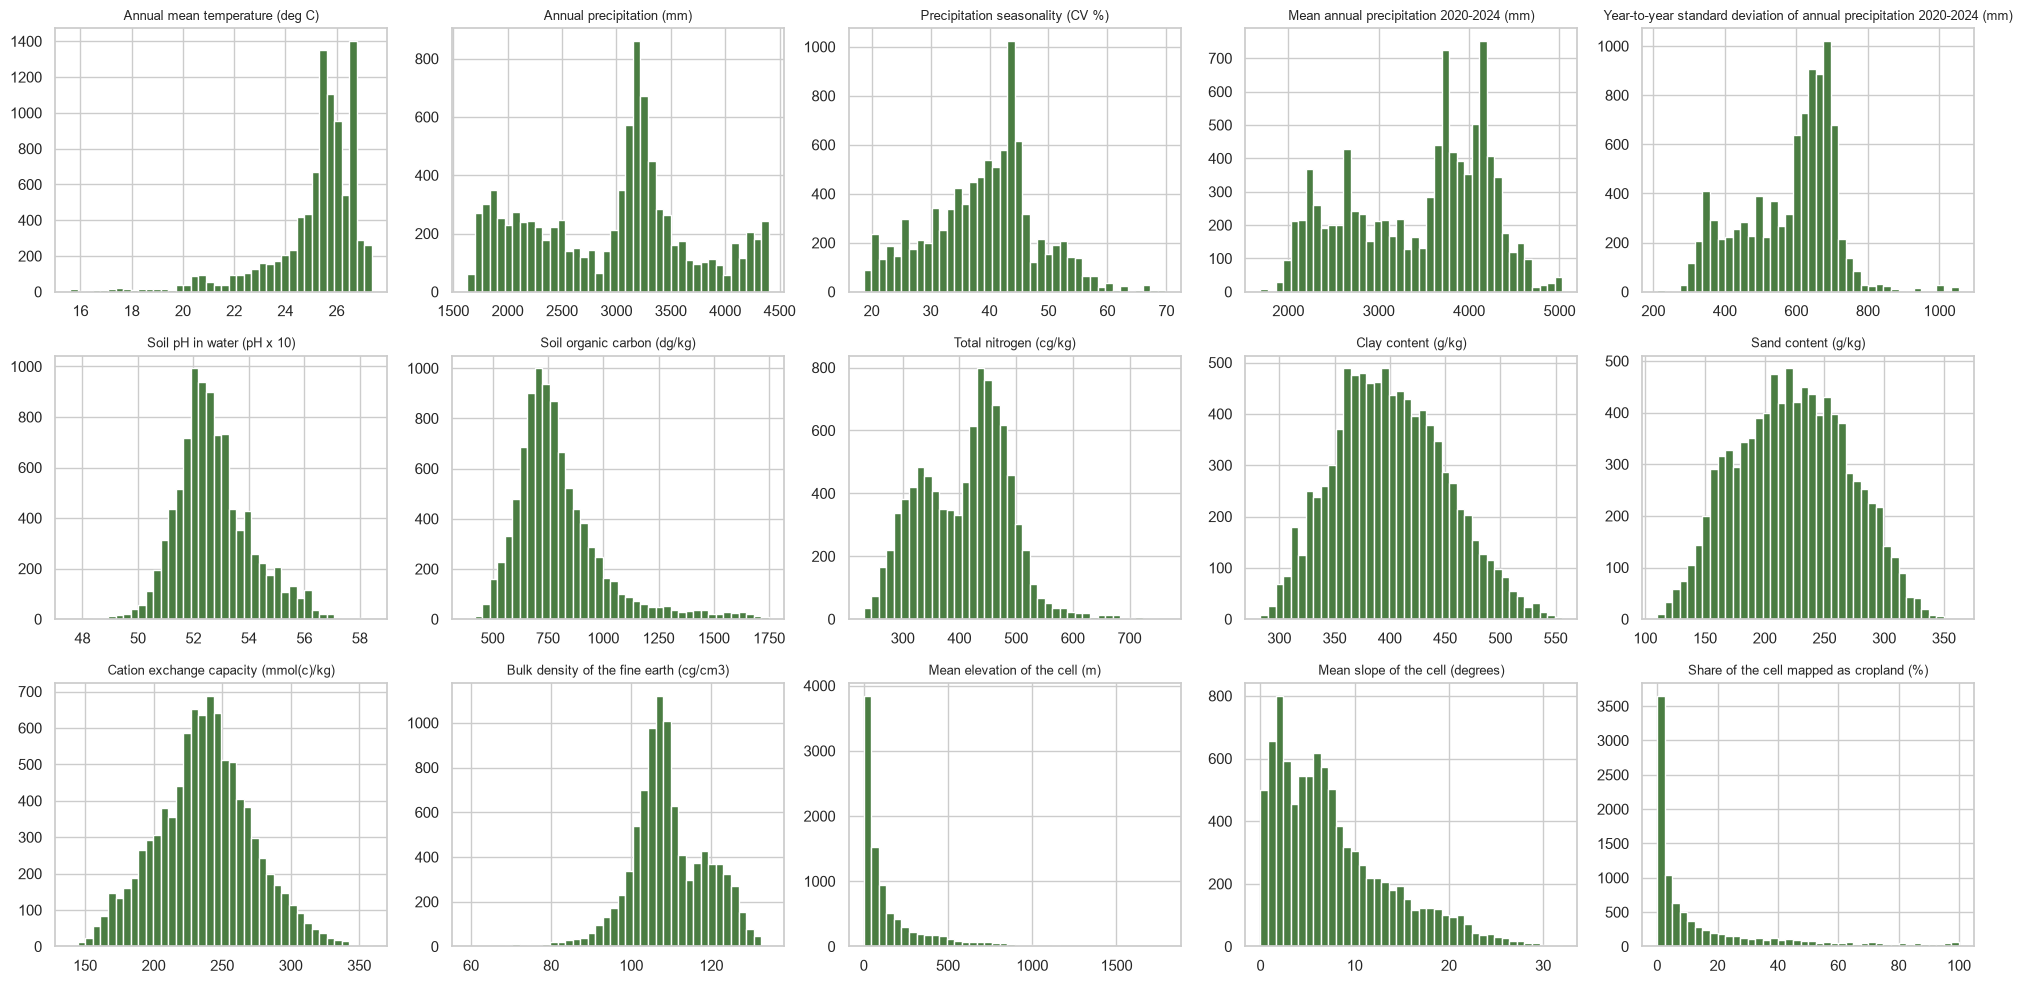

In [3]:
display(df[DRIVERS + ["cropland_pct"]].describe().T.round(2))
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, col in zip(axes.ravel(), DRIVERS + ["cropland_pct"]):
    ax.hist(df[col].dropna(), bins=40, color="#4A7D42")
    ax.set_title(C.nice(col), fontsize=9)
plt.tight_layout()
fig.savefig(FIG_DIR / "drivers_distributions.png", dpi=130)
plt.show()

## 3. GAEZ v5 suitability at 1 km, and how it compares with ~9 km

In [4]:
rows = []
for c in CROPS:
    k1, k9 = df[f"gaez1k_index_{c}"], df[f"gaez_index_{c}"]
    ok = k1.notna()
    rows.append({"crop": NAMES[c], "mean 1 km": k1.mean(), "max 1 km": k1.max(), "cells >= 5,000 (1 km)": int((k1 >= 5000).sum()),
                 "cells >= 5,000 (~9 km)": int((k9 >= 5000).sum()), "cells without a 1 km value": int((~ok).sum()),
                 "Spearman ~9 km vs 1 km": k9[ok].rank().corr(k1[ok].rank())})
pd.DataFrame(rows).set_index("crop").round(2)

,mean 1 km,max 1 km,"cells >= 5,000 (1 km)","cells >= 5,000 (~9 km)",cells without a 1 km value,Spearman ~9 km vs 1 km
crop,,,,,,
Rice,3050.38,9662.00,2181,2001,204,0.89
Maize,1335.23,5521.00,8,0,204,0.89
Cassava,3922.94,9723.50,3060,3154,204,0.88
Soybean,1763.88,7212.75,256,87,204,0.87
Oil palm,4407.87,9758.00,3938,3957,204,0.88
Rubber,2278.39,3333.00,0,0,204,0.82
Sugarcane,2346.25,5556.00,1186,669,204,0.89
Coffee,3806.26,9730.75,3110,2660,23,0.88
Cacao,3174.94,9375.00,2508,1297,23,0.86


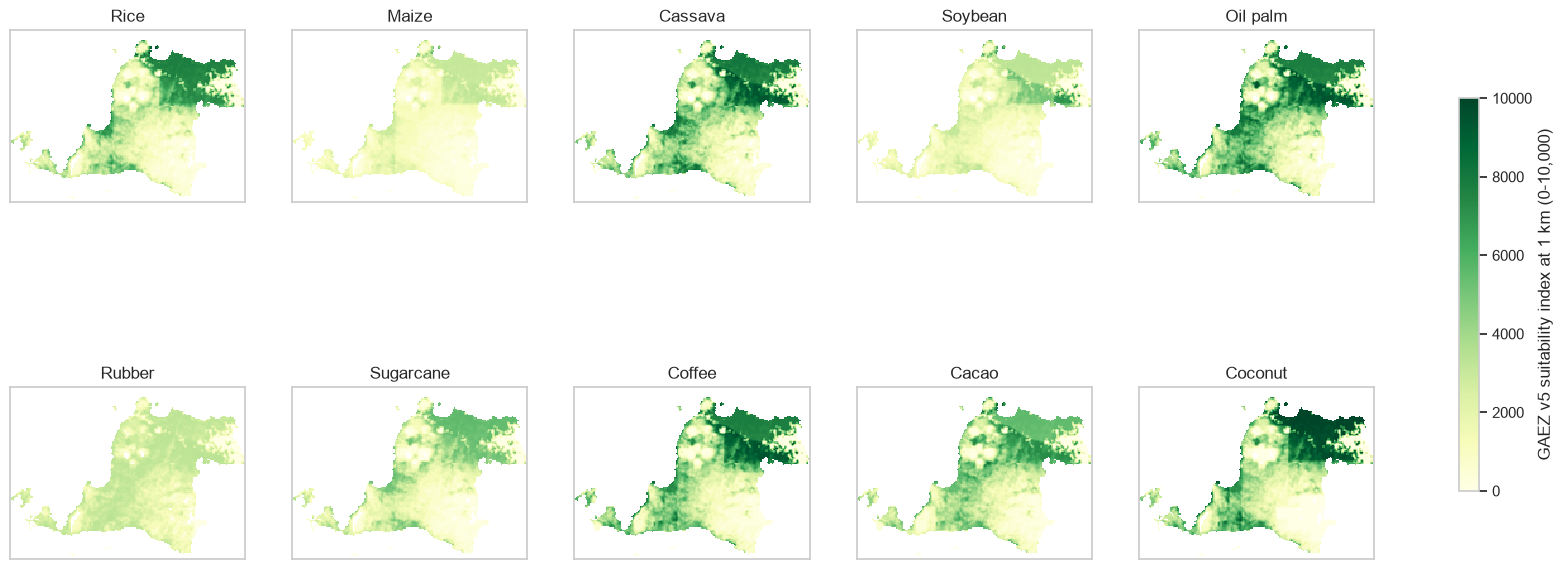

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
for ax, c in zip(axes.ravel(), CROPS):
    im = ax.imshow(on_grid(df[f"gaez1k_index_{c}"]), origin="lower", cmap="YlGn", vmin=0, vmax=10000, interpolation="nearest")
    ax.set_title(NAMES[c])
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.6, label="GAEZ v5 suitability index at 1 km (0-10,000)")
fig.savefig(FIG_DIR / "gaez1k_every_crop.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Crop recommendation at 1 km

The dashboard's rule (`common.recommend`). Absolute: the highest index wins, a runner-up within 500 points is a tie, and
below 5,000 the cell is 'Not recommended'. Relative: among crops reaching 5,000, the one strongest relative to its own range
in Banten wins. Cells where GAEZ gives no value for any crop are 'No cropland / water'.

,Absolute,Relative
label,,
Not recommended,56.4,56.4
Coffee,0.3,10.2
Coconut,12.0,9.2
Oil palm,9.7,6.2
Cacao,0.1,5.8
Cassava,0.0,5.2
Rice,0.0,4.0
Sugarcane,0.0,1.4
Soybean,0.0,1.4


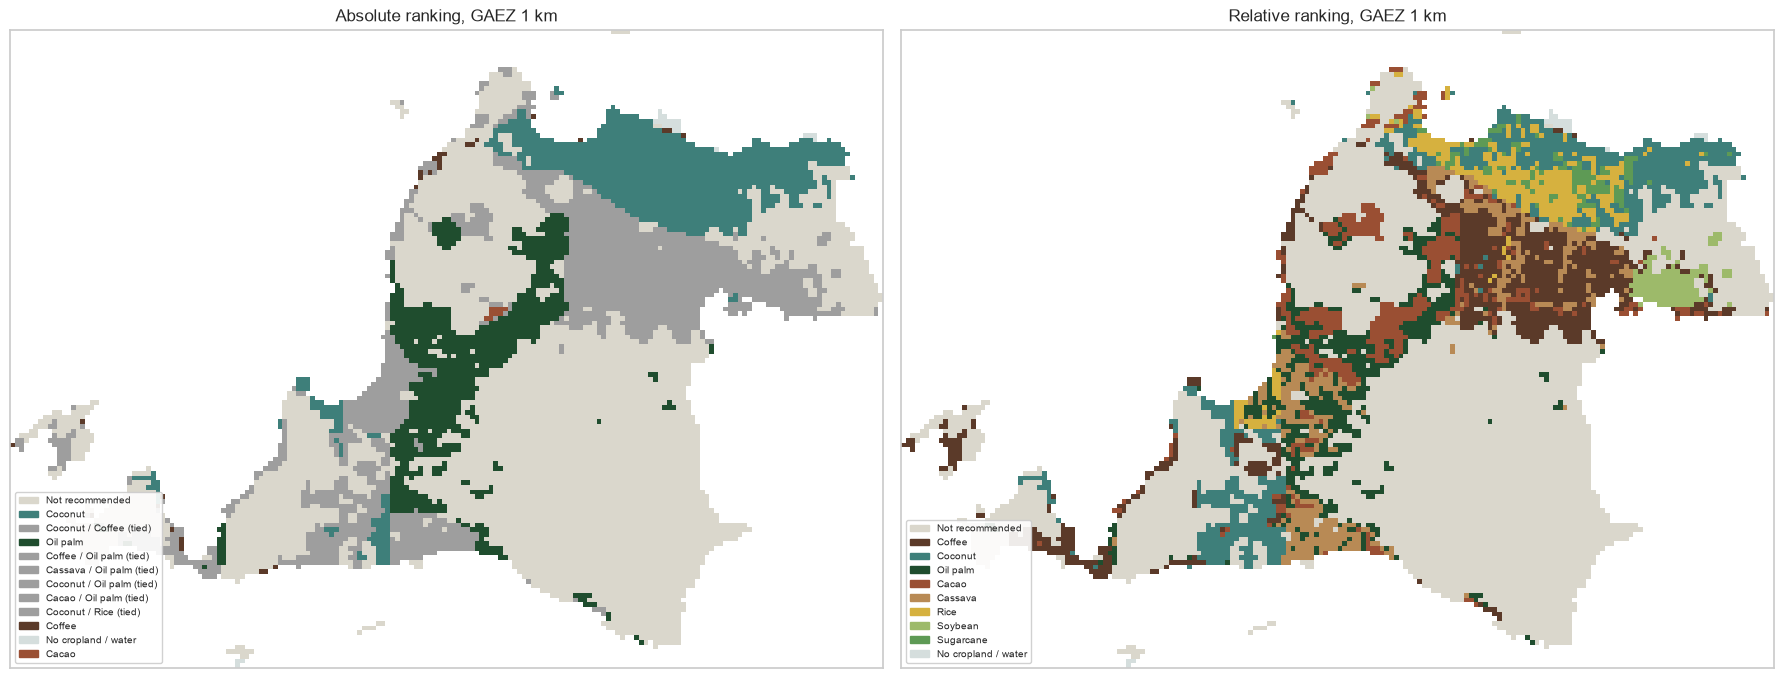

In [6]:
rec = {rk: C.recommend(df, CROPS, rk, res="1 km")["label"] for rk in ["Absolute", "Relative"]}
shares = pd.DataFrame({rk: lab.value_counts(normalize=True).mul(100).round(1) for rk, lab in rec.items()}).fillna(0)
display(shares.sort_values("Relative", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (rk, lab) in zip(axes, rec.items()):
    cats = list(lab.value_counts().index)
    colors = [C.LABEL_COLORS.get(k, "#9E9E9E") for k in cats]
    code_ = lab.map({k: i for i, k in enumerate(cats)})
    ax.imshow(on_grid(code_), origin="lower", cmap=plt.matplotlib.colors.ListedColormap(colors), vmin=-0.5,
              vmax=len(cats) - 0.5, interpolation="nearest")
    ax.set_title(f"{rk} ranking, GAEZ 1 km")
    ax.set_xticks([])
    ax.set_yticks([])
    handles = [plt.matplotlib.patches.Patch(color=col, label=k) for k, col in zip(cats[:12], colors[:12])]
    ax.legend(handles=handles, loc="lower left", fontsize=7, framealpha=0.9)
plt.tight_layout()
fig.savefig(FIG_DIR / "recommendation_1km.png", dpi=130)
plt.show()

## 5. Which conditions go with high suitability? (Spearman, drivers vs GAEZ 1 km)

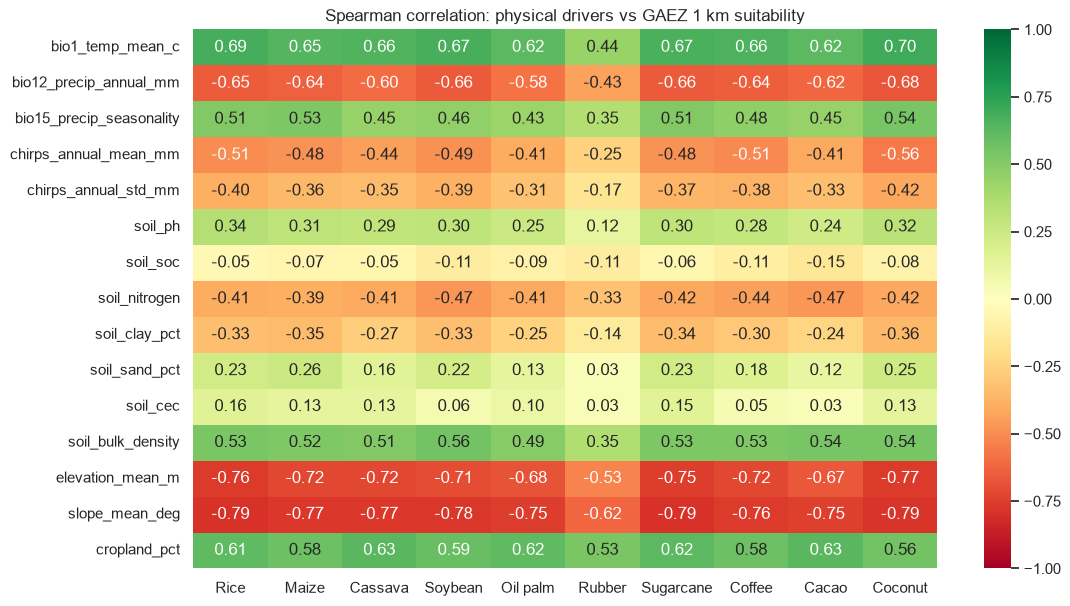

In [7]:
corr = df[DRIVERS + ["cropland_pct"] + [f"gaez1k_index_{c}" for c in CROPS]].corr(method="spearman")
dm = corr.loc[DRIVERS + ["cropland_pct"], [f"gaez1k_index_{c}" for c in CROPS]]
dm.columns = [NAMES[c] for c in CROPS]
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(dm, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, ax=ax)
ax.set(title="Spearman correlation: physical drivers vs GAEZ 1 km suitability", xlabel="", ylabel="")
fig.savefig(FIG_DIR / "drivers_vs_gaez1k.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Land cover and what Sentinel-2 sees

,s2_NDVI_mean,s2_NDMI_mean,s2_EVI_mean,s2_B11_mean,s2_valid_frac,cells
land_cover,,,,,,
Tree cover,0.731,0.242,0.517,0.186,0.937,6989
Cropland,0.516,0.151,0.355,0.195,0.932,1282
Built-up,0.329,-0.018,0.226,0.226,0.967,772
Permanent water bodies,0.207,0.218,0.150,0.109,0.769,193
Grassland,0.451,0.055,0.326,0.239,0.889,76
Herbaceous wetland,0.354,0.164,0.231,0.144,0.913,12
Mangroves,0.797,0.452,0.518,0.108,0.678,7
Bare / sparse vegetation,0.176,-0.037,0.128,0.253,0.908,2


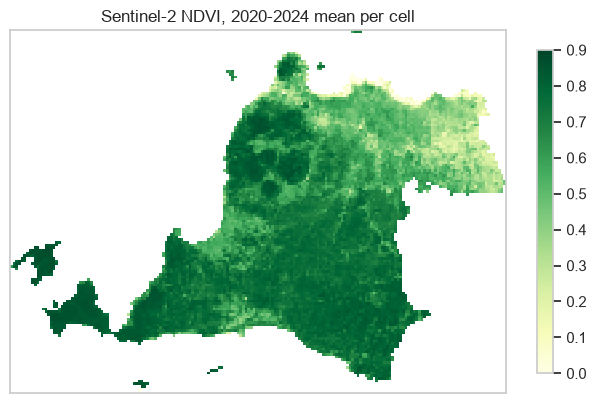

In [8]:
lc = df["landcover_majority"].round().map(C.WORLDCOVER_CLASSES).fillna("Unknown")
s2cols = [c for c in ["s2_NDVI_mean", "s2_NDMI_mean", "s2_EVI_mean", "s2_B11_mean", "s2_valid_frac"] if c in df]
display(df.assign(land_cover=lc).groupby("land_cover")[s2cols].mean().round(3).assign(cells=lc.value_counts()).sort_values("cells", ascending=False))
if "s2_NDVI_mean" in df:
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(on_grid(df["s2_NDVI_mean"]), origin="lower", cmap="YlGn", vmin=0, vmax=0.9, interpolation="nearest")
    ax.set(title="Sentinel-2 NDVI, 2020-2024 mean per cell")
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.7)
    fig.savefig(FIG_DIR / "sentinel2_ndvi.png", dpi=130, bbox_inches="tight")
    plt.show()

## 7. Two products: GAEZ 1 km vs Global Crop Suitability 2024

In [9]:
rows = []
for c in C.GCS_CROPS:
    g, s = df[f"gaez1k_index_{c}"], df[f"gcs2024_{c}"]
    ok = g.notna() & s.notna()
    rows.append({"crop": NAMES[c], "cells": int(ok.sum()), "Spearman": g[ok].rank().corr(s[ok].rank()),
                 "suitable in GAEZ (>= 5,000)": (g[ok] >= 5000).mean(), "suitable in GCS (>= 0.5)": (s[ok] >= 0.5).mean()})
pd.DataFrame(rows).set_index("crop").round(3)

,cells,Spearman,"suitable in GAEZ (>= 5,000)",suitable in GCS (>= 0.5)
crop,,,,
Rice,9043,0.742,0.232,0.741
Maize,9043,0.357,0.001,0.090
Cassava,9043,0.357,0.329,0.939
Soybean,9043,-0.206,0.028,0.016
Oil palm,9043,0.534,0.426,0.758
Sugarcane,9043,0.766,0.122,0.878


## 8. Irrigated (used) vs rain-fed (audit) scenario at 1 km, every crop

In [10]:
rows = []
for c in CROPS:
    irr, rf = df[f"gaez1k_index_{c}"], df[f"gaez1k_index_{c}_rainfed"]
    rows.append({"crop": NAMES[c], "mean irrigated": irr.mean(), "mean rain-fed": rf.mean(),
                 "cells >= 5,000 irrigated": int((irr >= 5000).sum()), "cells >= 5,000 rain-fed": int((rf >= 5000).sum())})
pd.DataFrame(rows).set_index("crop").round(0)

,mean irrigated,mean rain-fed,"cells >= 5,000 irrigated","cells >= 5,000 rain-fed"
crop,,,,
Rice,3050.0,2860.0,2181,2057
Maize,1335.0,1286.0,8,7
Cassava,3923.0,3852.0,3060,3065
Soybean,1764.0,1596.0,256,73
Oil palm,4408.0,4388.0,3938,4043
Rubber,2278.0,2263.0,0,0
Sugarcane,2346.0,2304.0,1186,1181
Coffee,3806.0,3859.0,3110,3178
Cacao,3175.0,3226.0,2508,2553


## 9. Spatial autocorrelation (Moran's I, rook neighbours on the 1 km grid)

In [11]:
def morans_i(values):
    z = on_grid(values)
    z = z - np.nanmean(z)
    num, w = 0.0, 0
    for a, b in [(z[:, :-1], z[:, 1:]), (z[:-1, :], z[1:, :])]:
        ok = ~np.isnan(a) & ~np.isnan(b)
        num += 2 * np.sum(a[ok] * b[ok])
        w += 2 * ok.sum()
    return (np.sum(~np.isnan(z)) / w) * num / np.nansum(z ** 2)


cols = DRIVERS + [f"gaez1k_index_{c}" for c in CROPS] + [c for c in ["s2_NDVI_mean"] if c in df]
pd.Series({c: morans_i(df[c]) for c in cols}, name="Moran's I").sort_values().round(3).to_frame()

,Moran's I
soil_ph,0.861
s2_NDVI_mean,0.881
gaez1k_index_rubber,0.904
soil_cec,0.907
soil_bulk_density,0.912
slope_mean_deg,0.924
soil_soc,0.928
gaez1k_index_soybean,0.933
gaez1k_index_cacao,0.936
gaez1k_index_oilpalm,0.936


## 10. Principal components of the 14 drivers

In [12]:
X = df[DRIVERS].fillna(df[DRIVERS].median())
Z = ((X - X.mean()) / X.std()).to_numpy()
_, S, Vt = np.linalg.svd(Z, full_matrices=False)
explained = S ** 2 / np.sum(S ** 2)
display(pd.DataFrame({"explained": explained[:5], "cumulative": np.cumsum(explained)[:5]},
                     index=[f"PC{i + 1}" for i in range(5)]).round(3))
pd.DataFrame(Vt[:3].T, index=DRIVERS, columns=["PC1", "PC2", "PC3"]).round(2)

,explained,cumulative
PC1,0.488,0.488
PC2,0.170,0.658
PC3,0.113,0.771
PC4,0.062,0.833
PC5,0.042,0.875


,PC1,PC2,PC3
bio1_temp_mean_c,-0.32,0.24,0.26
bio12_precip_annual_mm,0.36,0.01,0.05
bio15_precip_seasonality,-0.28,-0.10,0.21
chirps_annual_mean_mm,0.33,0.10,0.13
chirps_annual_std_mm,0.29,0.17,0.14
soil_ph,-0.20,-0.35,0.24
soil_soc,0.17,-0.36,0.25
soil_nitrogen,0.28,-0.26,0.28
soil_clay_pct,0.22,0.39,0.28
soil_sand_pct,-0.18,-0.42,-0.34


## Key numbers

In [13]:
abs_lab, rel_lab = rec["Absolute"], rec["Relative"]
best_crop = max(CROPS, key=lambda c: (df[f"gaez1k_index_{c}"] >= 5000).sum())
summary = {
    "cells (1 km)": len(df),
    "columns (fact table + Sentinel-2)": df.shape[1],
    "cells with a 1 km GAEZ value for all ten crops": int(df[[f"gaez1k_index_{c}" for c in CROPS]].notna().all(axis=1).sum()),
    "crop suitable (>= 5,000) in the most cells": f"{NAMES[best_crop]} ({int((df[f'gaez1k_index_{best_crop}'] >= 5000).sum()):,})",
    "share 'Not recommended', absolute rule": f"{(abs_lab == 'Not recommended').mean():.1%}",
    "share 'Not recommended', relative rule": f"{(rel_lab == 'Not recommended').mean():.1%}",
    "most frequent winner, relative rule": rel_lab[~rel_lab.isin(['Not recommended', 'No cropland / water'])].value_counts().index[0],
    "driver most correlated with rice (Spearman)": dm["Rice"].abs().idxmax(),
}
pd.Series(summary, name="value").to_frame()

,value
cells (1 km),9333
columns (fact table + Sentinel-2),139
cells with a 1 km GAEZ value for all ten crops,9129
"crop suitable (>= 5,000) in the most cells","Oil palm (3,938)"
"share 'Not recommended', absolute rule",56.4%
"share 'Not recommended', relative rule",56.4%
"most frequent winner, relative rule",Coffee
driver most correlated with rice (Spearman),slope_mean_deg
